In [1]:
import pandas as pd
import numpy as np
import duckdb
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.formula.api import ols

In [2]:
#Load free penguin data and drop rows with missing values for body mass and species
df = sns.load_dataset('penguins').dropna(subset=['body_mass_g', 'species'])

In [3]:
df.dtypes

species               object
island                object
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                   object
dtype: object

In [4]:
#look at what we have for islands and species
duckdb.sql("""select island
                    ,species
                    ,count(body_mass_g) as row_count
                    ,avg(body_mass_g) as avg_body_mass
            from df
            group by island
                    ,species""").df()

,island,species,row_count,avg_body_mass
0,Torgersen,Adelie,51,3706.372549
1,Biscoe,Adelie,44,3709.659091
2,Biscoe,Gentoo,123,5076.016260
3,Dream,Adelie,56,3688.392857
4,Dream,Chinstrap,68,3733.088235


In [5]:
#function to create box and whisker plots
def box_whisker(cat1,cat2,interval):
    sns.set_theme(style="whitegrid")
    fig, ax = plt.subplots(figsize=(8, 5))

    sns.boxplot(
        data=df,
        x=cat1,
        y=interval,
        hue=cat2,  #splits each category by a second variable
        palette="Dark2",  #Color palette
        width=0.6,  #Width of the boxes
        fliersize=4,  # Size of outlier dots
        ax=ax,
    )
    ax.set_title("Penguin Plot", fontsize=13, pad=12)
    ax.set_xlabel(cat1)
    ax.set_ylabel(interval)
    ax.legend(title=cat2)

    plt.tight_layout()
    plt.show()

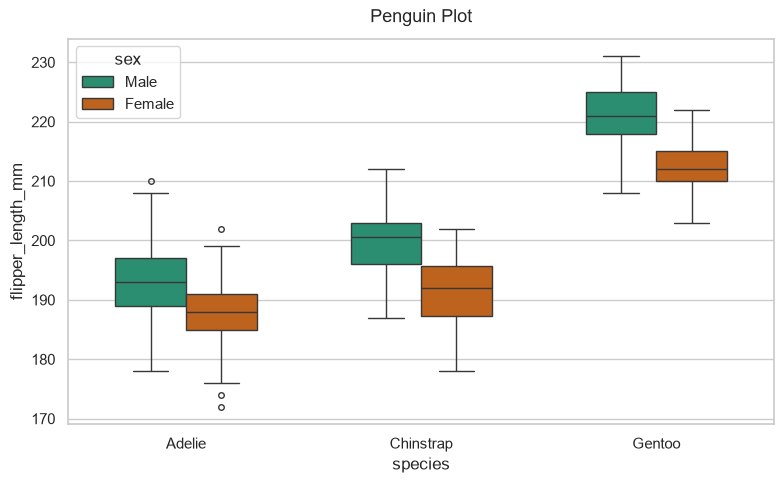

In [6]:
box_whisker("species","sex","flipper_length_mm")
#box_whisker("species","sex","bill_length_mm")
#box_whisker("species","sex","body_mass_g")
#box_whisker("species","island","body_mass_g")

In [7]:
# Fit the OLS model and run the ANOVA table
model = ols('body_mass_g ~ C(species) + C(sex)', data=df).fit()
anova_table = sm.stats.anova_lm(model, typ=2)

print(anova_table)

                  sum_sq     df           F         PR(>F)
C(species)  1.434016e+08    2.0  715.286340  1.618971e-120
C(sex)      3.709026e+07    1.0  370.012058   8.729411e-56
Residual    3.297919e+07  329.0         NaN            NaN


In [8]:
#Added Eta-Squared, proportion of total variance explained
anova_table["eta_sq"] = anova_table["sum_sq"] / anova_table["sum_sq"].sum()
print(anova_table)

                  sum_sq     df           F         PR(>F)    eta_sq
C(species)  1.434016e+08    2.0  715.286340  1.618971e-120  0.671761
C(sex)      3.709026e+07    1.0  370.012058   8.729411e-56  0.173748
Residual    3.297919e+07  329.0         NaN            NaN  0.154490
